In [215]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
path = r"C:\Users\radhe\OneDrive\Documents\Desktop\AI&ML PGD\Week3\Build1_DataPack\datapack\bookings\legacy"
# DATA_DIR = Path()
city = {'a':'\\ahmedabad','b':'\\bengaluru','c':'\\chennai','h':'\\hyderabad','j':'\\jaipur','p':'\\pune'}
os.listdir(Path(path+city['a']))
DATA_DIR = Path(path+city['a'])


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    r"C:\Users\radhe\OneDrive\Documents\Desktop\AI&ML PGD\Week3\Build1_DataPack\datapack\bookings\legacy"
)

city = {
    'a': 'ahmedabad',
    'b': 'bengaluru',
    'c': 'chennai',
    'h': 'hyderabad',
    'j': 'jaipur',
    'p': 'pune'
}

city_dfs = {}

for code, city_name in city.items():
    DATA_DIR = path / city_name

    files = sorted(DATA_DIR.rglob("bookings_*.csv.gz"))

    if files:
        city_dfs[city_name] = pd.concat(
            [
                pd.read_csv(
                    file,
                    compression="gzip",
                    encoding="latin1"
                )
                for file in files
            ],
            ignore_index=True
        )

        print(city_name, city_dfs[city_name])
    else:
        print(f"No files found for {city_name}")


ahmedabad                   booking_id        created_at           slot_at       city  \
0       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
1       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
2       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
3       BK-AHM-202501-000002  03/01/2025 05:18  06/01/2025 13:22  Ahmedabad   
4       BK-AHM-202501-000003  27/01/2025 10:46  28/01/2025 13:37  Ahmedabad   
...                      ...               ...               ...        ...   
235369  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235370  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235371  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235372  BK-AHM-202606-101582  07/06/2026 10:57  11/06/2026 17:52  Ahmedabad   
235373  BK-AHM-202606-101583  05/06/2026 14:16  07/06/2026 18:04  Ahmedabad   

       clinic_id channel  source   patien

In [259]:
campaign_file = Path(r"C:\Users\radhe\OneDrive\Documents\Desktop\AI&ML PGD\Week3\Build1_DataPack\datapack\campaigns") / "campaign_bookings.csv.gz"

campaign_df = pd.read_csv(
    campaign_file,
    compression="gzip",
    encoding="latin1"
)
#campaign_df.head()
campaign_df.head()

,booking_id,campaign_id,waiver_rs
0,BK-AHM-202601-065286,HC-FREE-2026Q1,150
1,BK-AHM-202601-065292,HC-FREE-2026Q1,150
2,BK-AHM-202601-065298,HC-FREE-2026Q1,150
3,BK-AHM-202601-065301,HC-FREE-2026Q1,150
4,BK-AHM-202601-065306,HC-FREE-2026Q1,150


In [258]:
patients_df = pd.read_csv(
    Path(r"C:\Users\radhe\OneDrive\Documents\Desktop\AI&ML PGD\Week3\Build1_DataPack\datapack\patients") / "patients.csv.gz",
    compression="gzip",
    encoding="latin1"
)

In [ ]:
def profile_table(df, name):
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum().sort_values(ascending=False))

    print("\nExact duplicate rows:", df.duplicated().sum())

profile_table(campaign_df, "Campaigns")
profile_table(patients_df, "Patients")


--- Campaigns ---
Shape: (48869, 3)

Data types:
booking_id       str
campaign_id      str
waiver_rs      int64
dtype: object

Missing values:
booking_id     0
campaign_id    0
waiver_rs      0
dtype: int64

Exact duplicate rows: 0

--- Patients ---
Shape: (309217, 6)

Data types:
patient_id      str
patient_name    str
phone           str
dob             str
city            str
signup_date     str
dtype: object

Missing values:
patient_id      0
patient_name    0
phone           0
dob             0
city            0
signup_date     0
dtype: int64

Exact duplicate rows: 0


In [ ]:
for city_name, df in city_dfs.items():
    print(f"\n--- {city_name} ---")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", df.columns.tolist())


--- ahmedabad ---
Shape: (235374, 12)
Missing values: 250
Duplicate rows: 0
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'patient_name', 'test_code', 'test_price', 'home_fee']

--- bengaluru ---
Shape: (301223, 12)
Missing values: 288
Duplicate rows: 3
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'patient_name', 'test_code', 'test_price', 'home_fee']

--- chennai ---
Shape: (202121, 12)
Missing values: 192
Duplicate rows: 3
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'patient_name', 'test_code', 'test_price', 'home_fee']

--- hyderabad ---
Shape: (220995, 12)
Missing values: 255
Duplicate rows: 5
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'patient_name', 'test_code', 'test_price', 'home_fee']

--- jaipur ---
Shape: (107920, 12)
Missing values: 10

In [255]:
import pandas as pd
import numpy as np

booking_frames = []

for city_name, df in city_dfs.items():
    temp = city_dfs[city_name].copy()
    print(df)
    temp["city"] = city_name
    booking_frames.append(temp)

bookings_df = pd.concat(booking_frames, ignore_index=True)

print("Total bookings rows:", len(bookings_df))
print("Columns:", bookings_df.columns.tolist())

print("\nRows per city:")
print(bookings_df.groupby("city").size())
for col in ["created_at", "slot_at"]:
    df[col] = pd.to_datetime(
        df[col],
        format=r"%d/%m/%Y %H:%M",
        errors="coerce"
    )
bookings_df.shape

                  booking_id        created_at           slot_at       city  \
0       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
1       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
2       BK-AHM-202501-000001  08/01/2025 03:16  09/01/2025 08:26  Ahmedabad   
3       BK-AHM-202501-000002  03/01/2025 05:18  06/01/2025 13:22  Ahmedabad   
4       BK-AHM-202501-000003  27/01/2025 10:46  28/01/2025 13:37  Ahmedabad   
...                      ...               ...               ...        ...   
235369  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235370  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235371  BK-AHM-202606-101581  14/06/2026 17:38  15/06/2026 19:03  Ahmedabad   
235372  BK-AHM-202606-101582  07/06/2026 10:57  11/06/2026 17:52  Ahmedabad   
235373  BK-AHM-202606-101583  05/06/2026 14:16  07/06/2026 18:04  Ahmedabad   

       clinic_id channel  source   patient_id  pati

(1252786, 12)

In [ ]:
missing_summary = bookings_df.isna().sum()

missing_summary = (
    missing_summary[missing_summary > 0]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(bookings_df) * 100
).round(3)

display(missing_summary)

,missing_count,missing_percent
test_code,1290,0.103


In [ ]:
print("Exact duplicate rows:", bookings_df.duplicated().sum())

print(
    "Duplicate booking IDs:",
    bookings_df["booking_id"].duplicated().sum()
)

duplicate_ids = bookings_df[
    bookings_df["booking_id"].duplicated(keep=False)
].sort_values("booking_id")

display(duplicate_ids.head(20))

Exact duplicate rows: 15
Duplicate booking IDs: 711321


,booking_id,created_at,slot_at,city,clinic_id,channel,source,patient_id,patient_name,test_code,test_price,home_fee
0,BK-AHM-202501-000001,08/01/2025 03:16,09/01/2025 08:26,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T009,800,0
1,BK-AHM-202501-000001,08/01/2025 03:16,09/01/2025 08:26,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T004,650,0
2,BK-AHM-202501-000001,08/01/2025 03:16,09/01/2025 08:26,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T007,550,0
4,BK-AHM-202501-000003,27/01/2025 10:46,28/01/2025 13:37,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T003,450,150
5,BK-AHM-202501-000003,27/01/2025 10:46,28/01/2025 13:37,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T017,450,150
6,BK-AHM-202501-000003,27/01/2025 10:46,28/01/2025 13:37,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T002,120,150
7,BK-AHM-202501-000003,27/01/2025 10:46,28/01/2025 13:37,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T006,650,150
9,BK-AHM-202501-000005,06/01/2025 08:21,11/01/2025 09:56,ahmedabad,AHM-03,clinic,app,PAHM0002520,Ritika Nair,T008,1100,0
10,BK-AHM-202501-000005,06/01/2025 08:21,11/01/2025 09:56,ahmedabad,AHM-03,clinic,app,PAHM0002520,Ritika Nair,T009,800,0
11,BK-AHM-202501-000006,10/01/2025 08:30,11/01/2025 11:28,ahmedabad,AHM-04,home,walkin,PAHM0018893,Kabir Khan,T016,160,150


In [ ]:
print(bookings_df.dtypes)

for col in ["created_at", "slot_at"]:
    bookings_df[col] = pd.to_datetime(
        bookings_df[col],
        errors="coerce"
    )

print("\nBooking creation date range:")
print(bookings_df["created_at"].min(), "to",
      bookings_df["created_at"].max())

print("\nAppointment slot date range:")
print(bookings_df["slot_at"].min(), "to",
      bookings_df["slot_at"].max())

booking_id         str
created_at         str
slot_at            str
city               str
clinic_id          str
channel            str
source             str
patient_id         str
patient_name       str
test_code          str
test_price      object
home_fee        object
dtype: object

Booking creation date range:
2025-01-01 00:00:00 to 2026-12-06 23:52:00

Appointment slot date range:
2025-01-01 06:00:00 to 2026-12-06 19:59:00


In [ ]:
print("CAMPAIGN TABLE")
print("Shape:", campaign_df.shape)
print(campaign_df.columns.tolist())
display(campaign_df.head(5))

print("\nPATIENT TABLE")
print("Shape:", patients_df.shape)
print(patients_df.columns.tolist())
display(patients_df.head(5))

CAMPAIGN TABLE
Shape: (48869, 3)
['booking_id', 'campaign_id', 'waiver_rs']


,booking_id,campaign_id,waiver_rs
0,BK-AHM-202601-065286,HC-FREE-2026Q1,150
1,BK-AHM-202601-065292,HC-FREE-2026Q1,150
2,BK-AHM-202601-065298,HC-FREE-2026Q1,150
3,BK-AHM-202601-065301,HC-FREE-2026Q1,150
4,BK-AHM-202601-065306,HC-FREE-2026Q1,150



PATIENT TABLE
Shape: (309217, 6)
['patient_id', 'patient_name', 'phone', 'dob', 'city', 'signup_date']


,patient_id,patient_name,phone,dob,city,signup_date
0,PAHM0030088,Rahul Fernandes,+91 85778 98441,1988-02-02,Ahmedabad,2023-01-14
1,PAHM0043743,Ananya D'Souza,+91 84824 41827,1992-11-13,Ahmedabad,2025-10-02
2,PAHM0011366,Rohan Mehta,+91 77327 81379,1944-07-05,Ahmedabad,2023-01-18
3,PAHM0009021,Vihaan Pillai,+91 76067 53849,1958-03-06,Ahmedabad,2022-08-06
4,PAHM0052680,Meera Desai,+91 81849 12697,2005-11-01,Ahmedabad,2026-05-19


In [ ]:
print("CAMPAIGN TABLE")
print("Shape:", campaign_df.shape)
print("Columns:", campaign_df.columns.tolist())
display(campaign_df.head(10))

print("\nPATIENT TABLE")
print("Shape:", patients_df.shape)
print("Columns:", patients_df.columns.tolist())
display(patients_df.head(10))

CAMPAIGN TABLE
Shape: (48869, 3)
Columns: ['booking_id', 'campaign_id', 'waiver_rs']


,booking_id,campaign_id,waiver_rs
0,BK-AHM-202601-065286,HC-FREE-2026Q1,150
1,BK-AHM-202601-065292,HC-FREE-2026Q1,150
2,BK-AHM-202601-065298,HC-FREE-2026Q1,150
3,BK-AHM-202601-065301,HC-FREE-2026Q1,150
4,BK-AHM-202601-065306,HC-FREE-2026Q1,150
5,BK-AHM-202601-065308,HC-FREE-2026Q1,150
6,BK-AHM-202601-065310,HC-FREE-2026Q1,150
7,BK-AHM-202601-065311,HC-FREE-2026Q1,150
8,BK-AHM-202601-065317,HC-FREE-2026Q1,150
9,BK-AHM-202601-065318,HC-FREE-2026Q1,150



PATIENT TABLE
Shape: (309217, 6)
Columns: ['patient_id', 'patient_name', 'phone', 'dob', 'city', 'signup_date']


,patient_id,patient_name,phone,dob,city,signup_date
0,PAHM0030088,Rahul Fernandes,+91 85778 98441,1988-02-02,Ahmedabad,2023-01-14
1,PAHM0043743,Ananya D'Souza,+91 84824 41827,1992-11-13,Ahmedabad,2025-10-02
2,PAHM0011366,Rohan Mehta,+91 77327 81379,1944-07-05,Ahmedabad,2023-01-18
3,PAHM0009021,Vihaan Pillai,+91 76067 53849,1958-03-06,Ahmedabad,2022-08-06
4,PAHM0052680,Meera Desai,+91 81849 12697,2005-11-01,Ahmedabad,2026-05-19
5,PAHM0040142,Manish Nair,+91 77339 15066,1993-05-21,Ahmedabad,2025-06-26
6,PAHM0031576,Aarav Pillai,+91 97588 60210,1990-06-15,Ahmedabad,2024-12-09
7,PAHM0031084,Meera Joshi,+91 95852 34405,2001-09-06,Ahmedabad,2023-08-14
8,PAHM0046376,Mary D'Souza,+91 74720 45867,1996-10-01,Ahmedabad,2025-12-12
9,PAHM0015250,Karan Gupta,+91 94632 45408,1997-10-06,Ahmedabad,2023-06-19


In [ ]:
repeated_ids = bookings_df[
    bookings_df["booking_id"].duplicated(keep=False)
].sort_values("booking_id")

print("Rows with repeated booking IDs:", len(repeated_ids))
display(repeated_ids.head(20))

Rows with repeated booking IDs: 1108064


,booking_id,created_at,slot_at,city,clinic_id,channel,source,patient_id,patient_name,test_code,test_price,home_fee
0,BK-AHM-202501-000001,2025-08-01 03:16:00,2025-09-01 08:26:00,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T009,800,0
1,BK-AHM-202501-000001,2025-08-01 03:16:00,2025-09-01 08:26:00,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T004,650,0
2,BK-AHM-202501-000001,2025-08-01 03:16:00,2025-09-01 08:26:00,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,Saanvi Bose,T007,550,0
4,BK-AHM-202501-000003,NaT,NaT,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T003,450,150
5,BK-AHM-202501-000003,NaT,NaT,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T017,450,150
6,BK-AHM-202501-000003,NaT,NaT,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T002,120,150
7,BK-AHM-202501-000003,NaT,NaT,ahmedabad,AHM-01,home,app,PAHM0027001,Sneha Menon,T006,650,150
9,BK-AHM-202501-000005,2025-06-01 08:21:00,2025-11-01 09:56:00,ahmedabad,AHM-03,clinic,app,PAHM0002520,Ritika Nair,T008,1100,0
10,BK-AHM-202501-000005,2025-06-01 08:21:00,2025-11-01 09:56:00,ahmedabad,AHM-03,clinic,app,PAHM0002520,Ritika Nair,T009,800,0
11,BK-AHM-202501-000006,2025-10-01 08:30:00,2025-11-01 11:28:00,ahmedabad,AHM-04,home,walkin,PAHM0018893,Kabir Khan,T016,160,150


In [ ]:
booking_level = (
    bookings_df
    .groupby("booking_id", as_index=False)
    .agg(
        created_at=("created_at", "first"),
        slot_at=("slot_at", "first"),
        city=("city", "first"),
        clinic_id=("clinic_id", "first"),
        channel=("channel", "first"),
        source=("source", "first"),
        patient_id=("patient_id", "first"),
        test_count=("test_code", "count"),
        test_revenue=("test_price", "sum"),
        home_fee=("home_fee", "first")
    )
)

print("Original test-level rows:", len(bookings_df))
print("Unique bookings:", len(booking_level))
print("Duplicate booking IDs remaining:",
      booking_level["booking_id"].duplicated().sum())

display(booking_level.head())

Original test-level rows: 1252786
Unique bookings: 541465
Duplicate booking IDs remaining: 0


,booking_id,created_at,slot_at,city,clinic_id,channel,source,patient_id,test_count,test_revenue,home_fee
0,BK-AHM-202501-000001,2025-08-01 03:16:00,2025-09-01 08:26:00,ahmedabad,AHM-03,clinic,walkin,PAHM0028525,3,2000,0
1,BK-AHM-202501-000002,2025-03-01 05:18:00,2025-06-01 13:22:00,ahmedabad,AHM-04,clinic,app,PAHM0031384,1,650,0
2,BK-AHM-202501-000003,NaT,NaT,ahmedabad,AHM-01,home,app,PAHM0027001,4,1670,150
3,BK-AHM-202501-000004,NaT,NaT,ahmedabad,AHM-03,clinic,app,PAHM0007069,1,160,0
4,BK-AHM-202501-000005,2025-06-01 08:21:00,2025-11-01 09:56:00,ahmedabad,AHM-03,clinic,app,PAHM0002520,2,1900,0


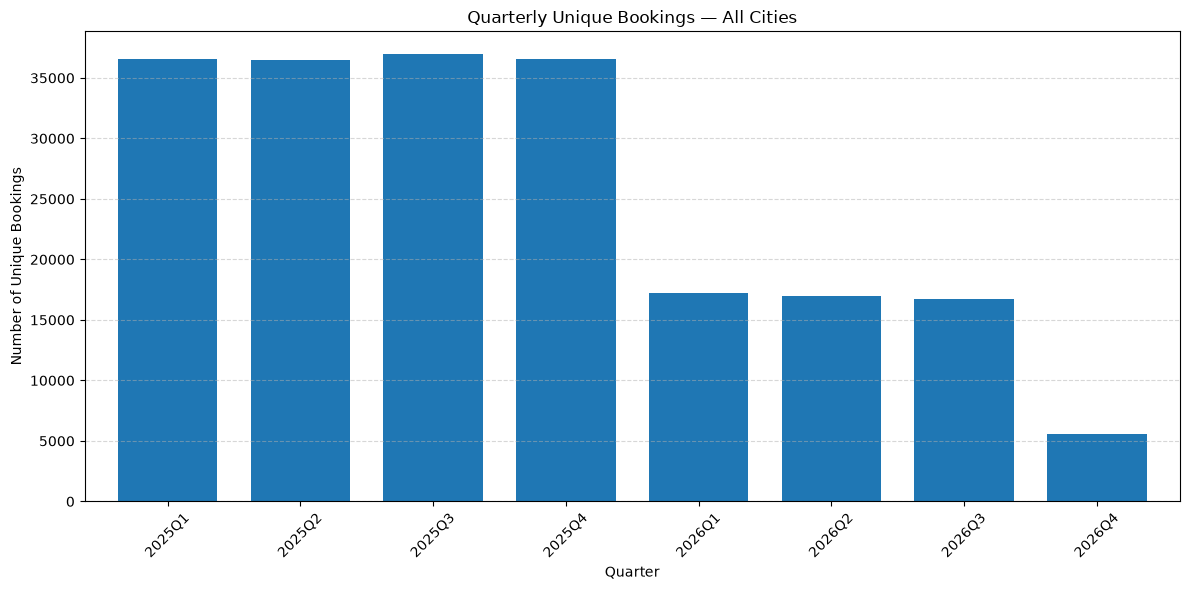

quarter
2025Q1    36531
2025Q2    36519
2025Q3    37000
2025Q4    36535
2026Q1    17213
2026Q2    16992
2026Q3    16735
2026Q4     5603
Freq: Q-DEC, Name: booking_id, dtype: int64


In [220]:

import pandas as pd
import matplotlib.pyplot as plt

# Ensure created_at is datetime
booking_level["created_at"] = pd.to_datetime(
    booking_level["created_at"], errors="coerce"
)

# Remove records with missing booking dates
data = booking_level.dropna(subset=["created_at"]).copy()

# Create year-quarter column
data["quarter"] = data["created_at"].dt.to_period("Q")

# Count unique bookings in each quarter
quarterly_bookings = (
    data.groupby("quarter")["booking_id"]
    .nunique()
    .sort_index()
)

# Plot quarterly unique bookings
plt.figure(figsize=(12, 6))
quarterly_bookings.plot(kind="bar", width=0.75)

plt.title("Quarterly Unique Bookings — All Cities")
plt.xlabel("Quarter")
plt.ylabel("Number of Unique Bookings")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(quarterly_bookings)


In [ ]:
date_check = bookings_df[
    bookings_df["booking_id"].str.contains(
        r"BK-.*-\d{6}-", na=False
    )
].copy()

date_check["id_month"] = date_check["booking_id"].str.extract(
    r"BK-[^-]+-(\d{4})(\d{2})-"
).agg("".join, axis=1)

date_check["created_month"] = (
    date_check["created_at"].dt.strftime("%Y%m")
)

date_check["month_mismatch"] = (
    date_check["id_month"] != date_check["created_month"]
)

print("Rows with ID/date month mismatch:",
      date_check["month_mismatch"].sum())

display(
    date_check.loc[
        date_check["month_mismatch"],
        ["booking_id", "created_at", "id_month", "created_month"]
    ].head(20)
)

Rows with ID/date month mismatch: 1211687


,booking_id,created_at,id_month,created_month
0,BK-AHM-202501-000001,2025-08-01 03:16:00,202501,202508
1,BK-AHM-202501-000001,2025-08-01 03:16:00,202501,202508
2,BK-AHM-202501-000001,2025-08-01 03:16:00,202501,202508
3,BK-AHM-202501-000002,2025-03-01 05:18:00,202501,202503
4,BK-AHM-202501-000003,NaT,202501,NaN
5,BK-AHM-202501-000003,NaT,202501,NaN
6,BK-AHM-202501-000003,NaT,202501,NaN
7,BK-AHM-202501-000003,NaT,202501,NaN
8,BK-AHM-202501-000004,NaT,202501,NaN
9,BK-AHM-202501-000005,2025-06-01 08:21:00,202501,202506


In [256]:
campaign_bookings = booking_level.merge(
    campaign_df[
        ["booking_id", "campaign_id", "waiver_rs"]
    ],
    on="booking_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

campaign_bookings["campaign_exposed"] = (
    campaign_bookings["campaign_id"].notna()
)

print(campaign_bookings["_merge"].value_counts())
display(
    campaign_bookings[
        ["booking_id", "created_at", "city",
         "campaign_id", "waiver_rs", "campaign_exposed"]
    ].head(10)
)

_merge
left_only     486584
both           43703
right_only         0
Name: count, dtype: int64


,booking_id,created_at,city,campaign_id,waiver_rs,campaign_exposed
0,BK-AHM-202501-000001,2025-08-01 03:16:00,ahmedabad,NaN,NaN,False
1,BK-AHM-202501-000002,2025-03-01 05:18:00,ahmedabad,NaN,NaN,False
2,BK-AHM-202501-000003,NaT,ahmedabad,NaN,NaN,False
3,BK-AHM-202501-000004,NaT,ahmedabad,NaN,NaN,False
4,BK-AHM-202501-000005,2025-06-01 08:21:00,ahmedabad,NaN,NaN,False
5,BK-AHM-202501-000006,2025-10-01 08:30:00,ahmedabad,NaN,NaN,False
6,BK-AHM-202501-000007,NaT,ahmedabad,NaN,NaN,False
7,BK-AHM-202501-000008,NaT,ahmedabad,NaN,NaN,False
8,BK-AHM-202501-000009,NaT,ahmedabad,NaN,NaN,False
9,BK-AHM-202501-000010,NaT,ahmedabad,NaN,NaN,False


In [ ]:
campaign_summary = (
    campaign_bookings
    .groupby("city")
    .agg(
        total_bookings=("booking_id", "nunique"),
        campaign_bookings=("campaign_exposed", "sum"),
        waiver_total=("waiver_rs", "sum")
    )
)

campaign_summary["campaign_share_pct"] = (
    campaign_summary["campaign_bookings"]
    / campaign_summary["total_bookings"] * 100
).round(2)

display(campaign_summary)
campaign_summary['campaign_bookings'].sum()/campaign_summary['total_bookings'].sum()

,total_bookings,campaign_bookings,waiver_total,campaign_share_pct
city,,,,
ahmedabad,101584,8564,1284600.0,8.43
bengaluru,130181,10973,1645950.0,8.43
chennai,87555,8235,1235250.0,9.41
hyderabad,95335,8075,1211250.0,8.47
jaipur,46831,4139,620850.0,8.84
pune,79979,6885,1032750.0,8.61


np.float64(0.08656330510744)

In [257]:

import pandas as pd

# Ensure dates are datetime
# booking_level["created_at"] = pd.to_datetime(
#     booking_level["created_at"], errors="coerce"
# )

# Define Q1 periods
q1_2025_start = pd.Timestamp("2025-01-01")
q1_2025_end   = pd.Timestamp("2025-04-01")

q1_2026_start = pd.Timestamp("2026-01-01")
q1_2026_end   = pd.Timestamp("2026-04-01")

# Select bookings created during each quarter
q1_2025 = booking_level[
    booking_level["created_at"].ge(q1_2025_start)
    & booking_level["created_at"].lt(q1_2025_end)
]

q1_2026 = booking_level[
    booking_level["created_at"].ge(q1_2026_start)
    & booking_level["created_at"].lt(q1_2026_end)
]

# Count unique bookings
bookings_2025 = q1_2025["booking_id"].count()
bookings_2026 = q1_2026["booking_id"].count()

booking_growth = (bookings_2026 - bookings_2025) / bookings_2025 * 100

print("Q1 2025 bookings:", bookings_2025)
print("Q1 2026 bookings:", bookings_2026)
print(f"Year-over-year booking growth: {booking_growth:.2f}%")


Q1 2025 bookings: 36531
Q1 2026 bookings: 17213
Year-over-year booking growth: -52.88%


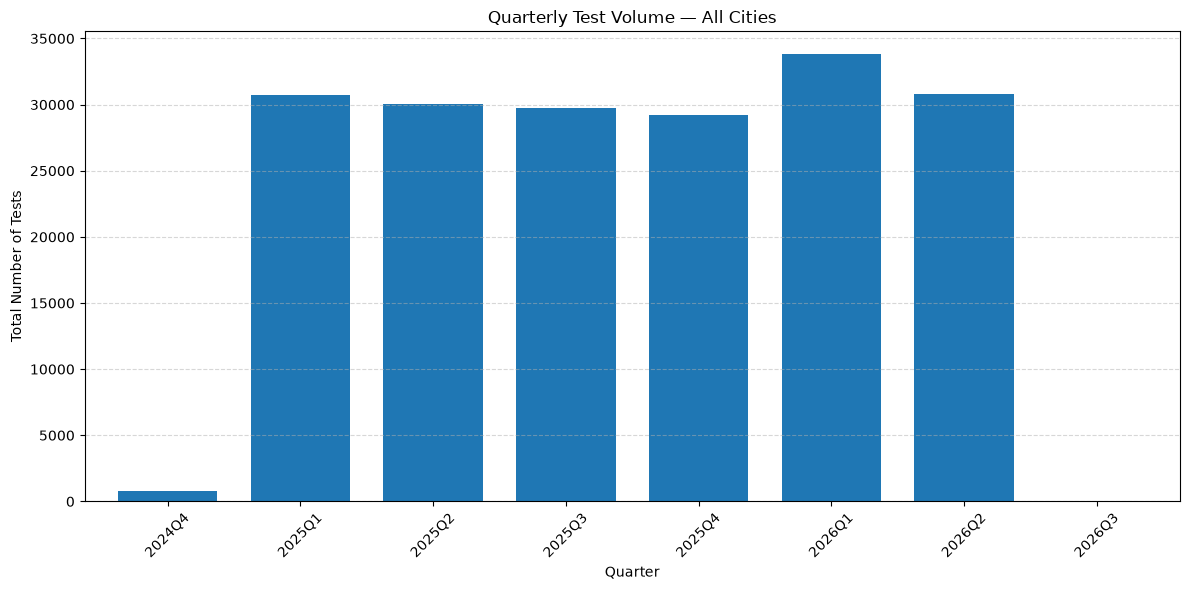

quarter
2024Q4      774
2025Q1    30700
2025Q2    30076
2025Q3    29736
2025Q4    29178
2026Q1    33849
2026Q2    30831
2026Q3        5
Freq: Q-DEC, dtype: int64


In [226]:
import pandas as pd
import matplotlib.pyplot as plt

df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

data = df.dropna(subset=["created_at"]).copy()

# Create quarter column
data["quarter"] = data["created_at"].dt.to_period("Q")

# Count test records per quarter
quarterly_tests = data.groupby("quarter").size()

# Plot
plt.figure(figsize=(12, 6))
quarterly_tests.plot(kind="bar", width=0.75)

plt.title("Quarterly Test Volume — All Cities")
plt.xlabel("Quarter")
plt.ylabel("Total Number of Tests")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(quarterly_tests)

Q1 2025 test volume: 30700
Q1 2026 test volume: 33849
Year-over-year test volume change: 10.26%


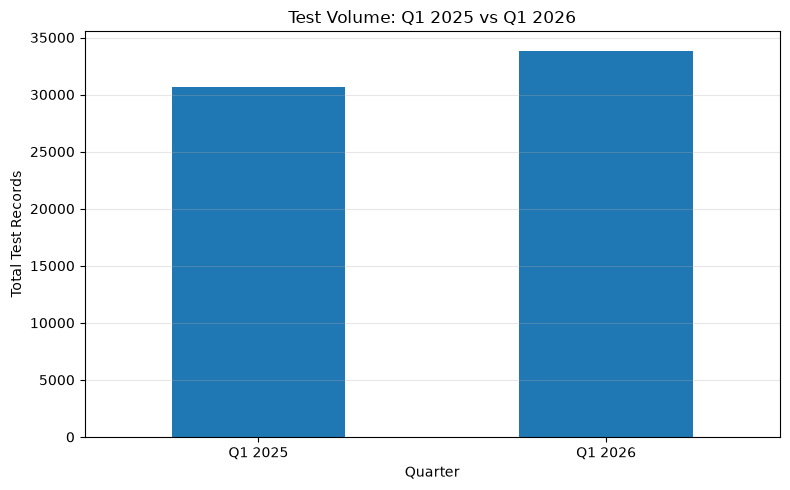

In [233]:

import pandas as pd
import matplotlib.pyplot as plt

# Ensure created_at is datetime
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

# Define Q1 periods
q1_2025 = df[
    (df["created_at"] >= "2025-01-01") &
    (df["created_at"] < "2025-04-01")
]

q1_2026 = df[
    (df["created_at"] >= "2026-01-01") &
    (df["created_at"] < "2026-04-01")
]

# Count test records
tests_2025 = len(q1_2025)
tests_2026 = len(q1_2026)

# Calculate percentage change
growth = (
    (tests_2026 - tests_2025) / tests_2025 * 100
    if tests_2025 > 0 else float("nan")
)

print("Q1 2025 test volume:", tests_2025)
print("Q1 2026 test volume:", tests_2026)
print(f"Year-over-year test volume change: {growth:.2f}%")

# Plot comparison
pd.Series(
    {"Q1 2025": tests_2025, "Q1 2026": tests_2026}
).plot(kind="bar", figsize=(8, 5))

plt.title("Test Volume: Q1 2025 vs Q1 2026")
plt.xlabel("Quarter")
plt.ylabel("Total Test Records")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Quarterly Test Revenue:
quarter
2024Q4      509966.0
2025Q1    19733417.0
2025Q2    19084899.0
2025Q3    19047796.0
2025Q4    18745554.0
2026Q1    23270425.0
2026Q2    21121633.0
2026Q3        3399.0
Freq: Q-DEC, Name: test_price, dtype: float64


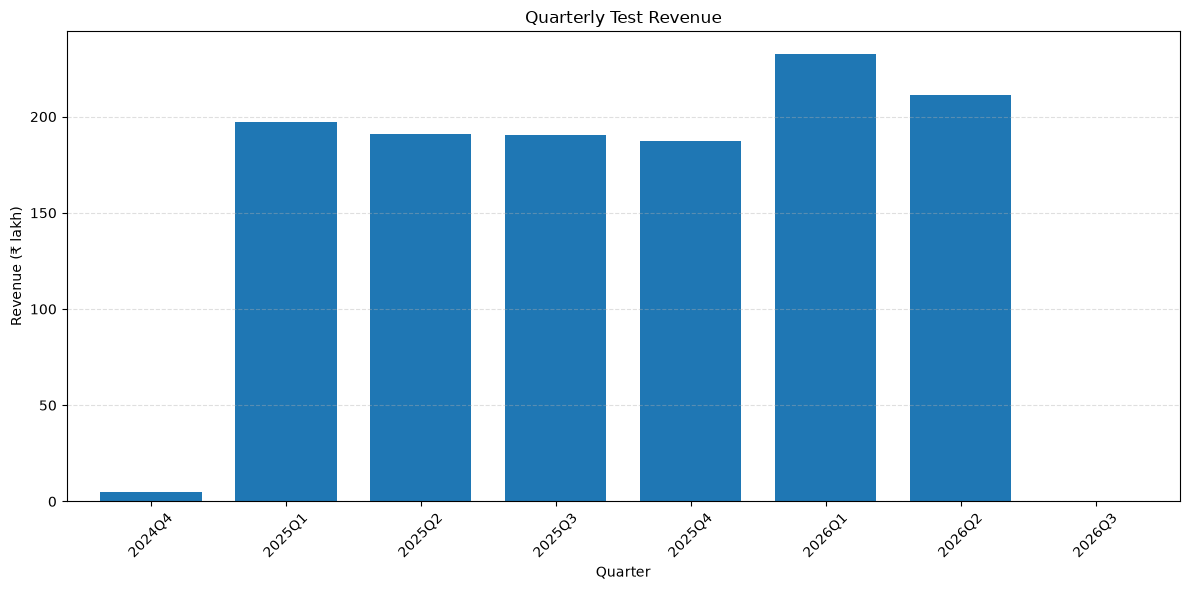


Q1 Revenue Comparison
Q1 2025 Revenue: ₹19,733,417.00
Q1 2026 Revenue: ₹23,270,425.00
Revenue Change: ₹3,537,008.00
Revenue Growth: 17.92%


In [234]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare data
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["test_price"] = pd.to_numeric(df["test_price"], errors="coerce")

# 2. Create quarter column
df["quarter"] = df["created_at"].dt.to_period("Q")

# 3. Calculate total revenue per quarter
quarterly_revenue = df.groupby("quarter")["test_price"].sum()

# 4. Print quarterly revenue
print("Quarterly Test Revenue:")
print(quarterly_revenue)

# 5. Plot quarterly revenue
plt.figure(figsize=(12, 6))
(quarterly_revenue / 100000).plot(kind="bar", width=0.75)

plt.title("Quarterly Test Revenue")
plt.xlabel("Quarter")
plt.ylabel("Revenue (₹ lakh)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 6. Compare Q1 2025 vs Q1 2026
revenue_2025 = quarterly_revenue.get(pd.Period("2025Q1"), 0)
revenue_2026 = quarterly_revenue.get(pd.Period("2026Q1"), 0)

change = revenue_2026 - revenue_2025
growth = (change / revenue_2025 * 100) if revenue_2025 else float("nan")

print("\nQ1 Revenue Comparison")
print(f"Q1 2025 Revenue: ₹{revenue_2025:,.2f}")
print(f"Q1 2026 Revenue: ₹{revenue_2026:,.2f}")
print(f"Revenue Change: ₹{change:,.2f}")
print(f"Revenue Growth: {growth:.2f}%")


In [235]:
patients_df.head(2)

,patient_id,patient_name,phone,dob,city,signup_date
0,PAHM0030088,Rahul Fernandes,+91 85778 98441,1988-02-02,Ahmedabad,2023-01-14
1,PAHM0043743,Ananya D'Souza,+91 84824 41827,1992-11-13,Ahmedabad,2025-10-02


C:\Users\radhe\AppData\Local\Temp\ipykernel_38192\1609396928.py:5: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  patients_df["signup_date"] = pd.to_datetime(


New Patients Registered per Quarter:
quarter
2022Q3    16359
2022Q4    19955
2023Q1    19331
2023Q2    19706
2023Q3    20014
2023Q4    19425
2024Q1    19549
2024Q2    19594
2024Q3    19580
2024Q4    19866
2025Q1    19577
2025Q2    19112
2025Q3    18737
2025Q4    18320
2026Q1    20455
2026Q2    19637
Freq: Q-DEC, Name: patient_id, dtype: int64


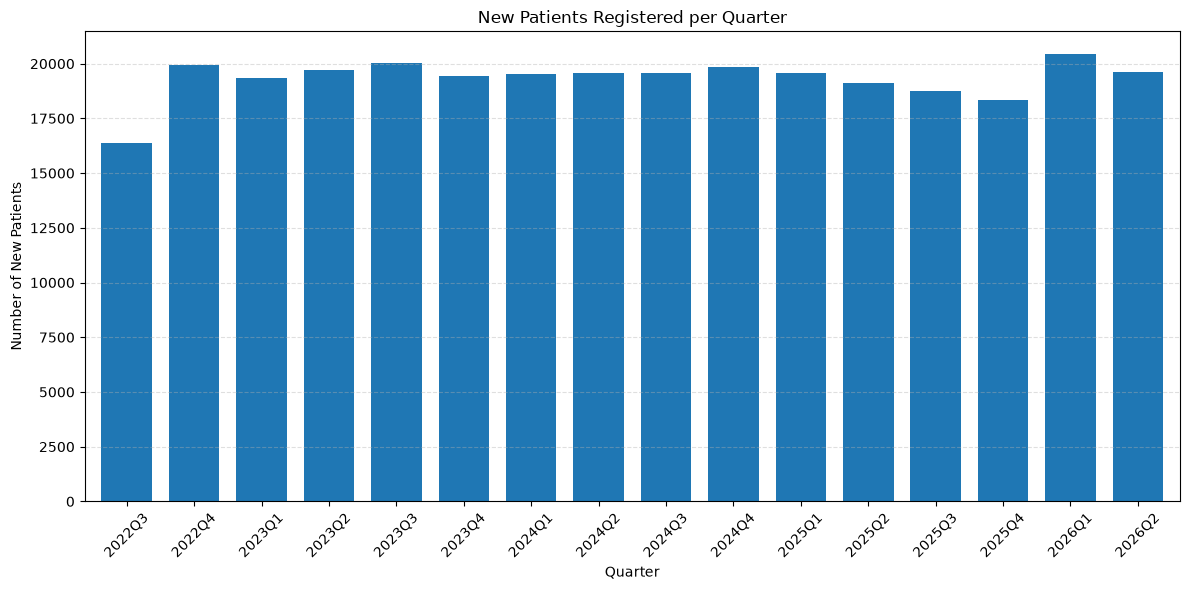


Q1 Comparison
Q1 2025: 19,577
Q1 2026: 20,455
Change: +878
Growth: 4.48%


In [236]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Convert signup_date to datetime
patients_df["signup_date"] = pd.to_datetime(
    patients_df["signup_date"], errors="coerce", dayfirst=True
)

# 2. Create quarter from signup date
patients_df["quarter"] = patients_df["signup_date"].dt.to_period("Q")

# 3. Count new patients registered per quarter
new_patients = (
    patients_df.dropna(subset=["patient_id", "signup_date"])
    .groupby("quarter")["patient_id"]
    .nunique()
    .sort_index()
)

print("New Patients Registered per Quarter:")
print(new_patients)

# 4. Plot quarterly new patient registrations
plt.figure(figsize=(12, 6))
new_patients.plot(kind="bar", width=0.75)

plt.title("New Patients Registered per Quarter")
plt.xlabel("Quarter")
plt.ylabel("Number of New Patients")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Compare Q1 2025 vs Q1 2026
q1_2025 = new_patients.get(pd.Period("2025Q1"), 0)
q1_2026 = new_patients.get(pd.Period("2026Q1"), 0)

change = q1_2026 - q1_2025
growth = (change / q1_2025 * 100) if q1_2025 else float("nan")

print("\nQ1 Comparison")
print(f"Q1 2025: {q1_2025:,}")
print(f"Q1 2026: {q1_2026:,}")
print(f"Change: {change:+,}")
print(f"Growth: {growth:.2f}%")


In [237]:

import pandas as pd

# 1. Convert dates
patients_df["signup_date"] = pd.to_datetime(
    patients_df["signup_date"], errors="coerce", dayfirst=True
)
booking_level["created_at"] = pd.to_datetime(
    booking_level["created_at"], errors="coerce", dayfirst=True
)

# 2. Identify new patients registered in Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

new_q1_patients = set(
    patients_df.loc[
        (patients_df["signup_date"] >= q1_start) &
        (patients_df["signup_date"] < q2_start),
        "patient_id"
    ].dropna()
)

# 3. Identify Q1 2026 bookings
q1_bookings = booking_level.loc[
    (booking_level["created_at"] >= q1_start) &
    (booking_level["created_at"] < q2_start)
].copy()

# 4. Find campaign-waiver bookings
campaign_bookings = set(
    campaign_df.loc[
        campaign_df["campaign_id"] == "HC-FREE-2026Q1",
        "booking_id"
    ].dropna()
)

waiver_bookings = q1_bookings[
    q1_bookings["booking_id"].isin(campaign_bookings)
]

# 5. Identify new patients who used the waiver
new_patients_with_waiver = set(
    waiver_bookings.loc[
        waiver_bookings["patient_id"].isin(new_q1_patients),
        "patient_id"
    ].dropna()
)

# 6. Calculate percentage
total_new_patients = len(new_q1_patients)
new_patients_using_waiver = len(new_patients_with_waiver)

percentage = (
    new_patients_using_waiver / total_new_patients * 100
    if total_new_patients > 0 else 0
)

print(f"New patients registered in Q1 2026: {total_new_patients:,}")
print(f"New patients who used the campaign waiver: {new_patients_using_waiver:,}")
print(f"Percentage using the waiver: {percentage:.2f}%")


New patients registered in Q1 2026: 20,455
New patients who used the campaign waiver: 1,374
Percentage using the waiver: 6.72%


Q1 2026 Test Volume
Total tests: 33,849
Tests from campaign-waiver bookings: 15,784
Share of total tests: 46.63%


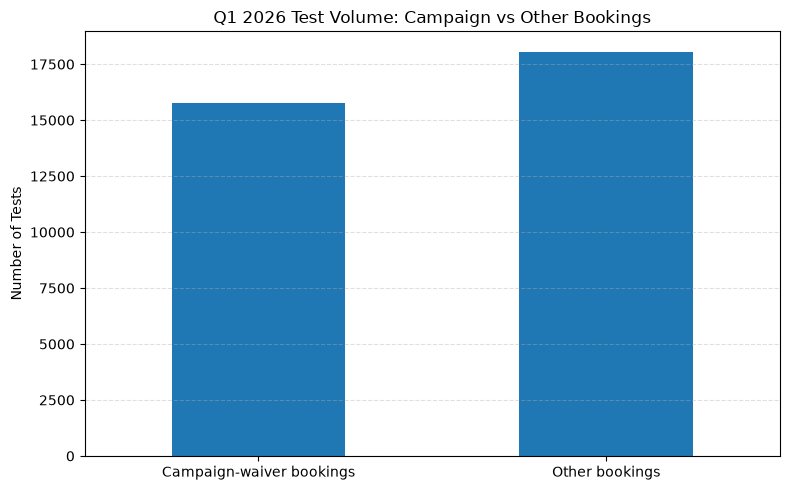

In [238]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Define Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

# 2. Identify Q1 2026 campaign-waiver booking IDs
campaign_booking_ids = set(
    campaign_df.loc[
        campaign_df["campaign_id"] == "HC-FREE-2026Q1",
        "booking_id"
    ].dropna()
)

# 3. Filter test-level data for Q1 2026
df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", dayfirst=True
)

q1_tests = df.loc[
    (df["created_at"] >= q1_start) &
    (df["created_at"] < q2_start)
].copy()

# 4. Count all tests and tests linked to campaign bookings
total_tests = len(q1_tests)

campaign_tests = q1_tests[
    q1_tests["booking_id"].isin(campaign_booking_ids)
]

campaign_test_volume = len(campaign_tests)

# 5. Calculate campaign share of test volume
campaign_test_share = (
    campaign_test_volume / total_tests * 100
    if total_tests > 0 else 0
)

print("Q1 2026 Test Volume")
print(f"Total tests: {total_tests:,}")
print(f"Tests from campaign-waiver bookings: {campaign_test_volume:,}")
print(f"Share of total tests: {campaign_test_share:.2f}%")

# 6. Optional: show tests by campaign booking vs other bookings
volume = pd.Series({
    "Campaign-waiver bookings": campaign_test_volume,
    "Other bookings": total_tests - campaign_test_volume
})

volume.plot(kind="bar", figsize=(8, 5))
plt.title("Q1 2026 Test Volume: Campaign vs Other Bookings")
plt.xlabel("")
plt.ylabel("Number of Tests")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


Q1 2026: Tests from New Patients Using Campaign Waiver
-------------------------------------------------------
All Q1 tests: 33,849
Tests from campaign-waiver bookings: 15,784
Tests from new patients using waiver: 5,045
Share of campaign tests: 31.96%
Share of all Q1 tests: 14.90%


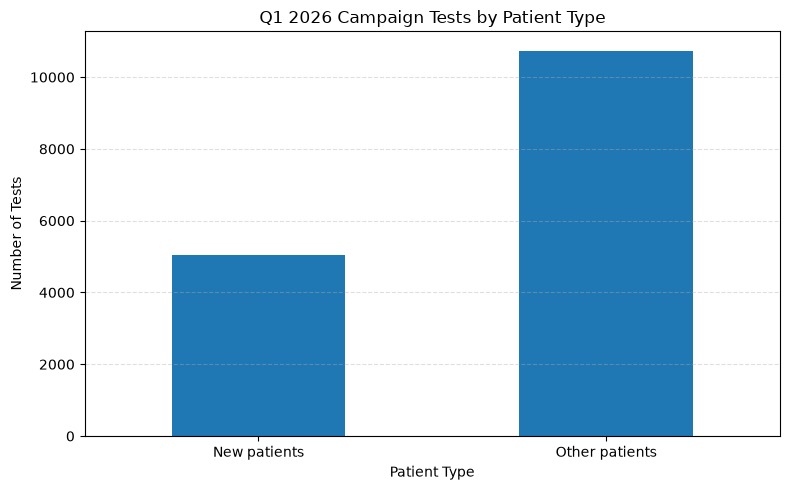

In [239]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Define Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

# 2. Identify patients newly registered in Q1 2026
patients_df["signup_date"] = pd.to_datetime(
    patients_df["signup_date"], errors="coerce", dayfirst=True
)

new_patient_ids = set(
    patients_df.loc[
        (patients_df["signup_date"] >= q1_start) &
        (patients_df["signup_date"] < q2_start),
        "patient_id"
    ].dropna()
)

# 3. Identify campaign-waiver booking IDs
campaign_booking_ids = set(
    campaign_df.loc[
        campaign_df["campaign_id"] == "HC-FREE-2026Q1",
        "booking_id"
    ].dropna()
)

# 4. Filter test-level data to Q1 2026
df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", dayfirst=True
)

q1_tests = df.loc[
    (df["created_at"] >= q1_start) &
    (df["created_at"] < q2_start)
].copy()

# 5. Tests associated with campaign-waiver bookings
campaign_tests = q1_tests[
    q1_tests["booking_id"].isin(campaign_booking_ids)
]

# 6. Of those tests, identify tests belonging to new patients
new_patient_campaign_tests = campaign_tests[
    campaign_tests["patient_id"].isin(new_patient_ids)
]

# 7. Calculate test counts and percentages
total_campaign_tests = len(campaign_tests)
new_patient_test_count = len(new_patient_campaign_tests)
total_q1_tests = len(q1_tests)

pct_of_campaign_tests = (
    new_patient_test_count / total_campaign_tests * 100
    if total_campaign_tests else 0
)

pct_of_all_q1_tests = (
    new_patient_test_count / total_q1_tests * 100
    if total_q1_tests else 0
)

print("Q1 2026: Tests from New Patients Using Campaign Waiver")
print("-" * 55)
print(f"All Q1 tests: {total_q1_tests:,}")
print(f"Tests from campaign-waiver bookings: {total_campaign_tests:,}")
print(f"Tests from new patients using waiver: {new_patient_test_count:,}")
print(f"Share of campaign tests: {pct_of_campaign_tests:.2f}%")
print(f"Share of all Q1 tests: {pct_of_all_q1_tests:.2f}%")

# 8. Visualize campaign test volume
other_campaign_tests = total_campaign_tests - new_patient_test_count

pd.Series({
    "New patients": new_patient_test_count,
    "Other patients": other_campaign_tests
}).plot(kind="bar", figsize=(8, 5))

plt.title("Q1 2026 Campaign Tests by Patient Type")
plt.xlabel("Patient Type")
plt.ylabel("Number of Tests")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [240]:

import pandas as pd

# Define Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

# Identify new patients registered in Q1 2026
patients_df["signup_date"] = pd.to_datetime(
    patients_df["signup_date"], errors="coerce", dayfirst=True
)

new_patient_ids = set(
    patients_df.loc[
        (patients_df["signup_date"] >= q1_start) &
        (patients_df["signup_date"] < q2_start),
        "patient_id"
    ].dropna()
)

# Identify campaign-waiver booking IDs
campaign_booking_ids = set(
    campaign_df.loc[
        campaign_df["campaign_id"] == "HC-FREE-2026Q1",
        "booking_id"
    ].dropna()
)

# Filter all tests in Q1 2026
df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", dayfirst=True
)

q1_tests = df.loc[
    (df["created_at"] >= q1_start) &
    (df["created_at"] < q2_start)
]

# Total test volume for the quarter
total_q1_tests = len(q1_tests)

# Tests from new patients with campaign-waiver bookings
new_patient_campaign_tests = q1_tests[
    q1_tests["booking_id"].isin(campaign_booking_ids) &
    q1_tests["patient_id"].isin(new_patient_ids)
]

new_patient_campaign_test_count = len(new_patient_campaign_tests)

# Percentage of the entire Q1 test volume
percentage = (
    new_patient_campaign_test_count / total_q1_tests * 100
    if total_q1_tests > 0 else 0
)

print(f"Total Q1 2026 test volume: {total_q1_tests:,}")
print(f"Tests from new patients using campaign waiver: {new_patient_campaign_test_count:,}")
print(f"Percentage of total test volume: {percentage:.2f}%")


Total Q1 2026 test volume: 33,849
Tests from new patients using campaign waiver: 5,045
Percentage of total test volume: 14.90%


In [242]:

# Inspect available DataFrames for event/history data
dataframes = {
    "df": df,
    "booking_level": booking_level,
    "patients_df": patients_df,
    "campaign_df": campaign_df
}

for name, data in dataframes.items():
    print(f"\n{'=' * 50}")
    print(f"DataFrame: {name}")
    print("Columns:", data.columns.tolist())

    relevant = [
        col for col in data.columns
        if any(word in col.lower() for word in [
            "resched", "event", "status", "cancel",
            "previous", "old_slot", "new_slot",
            "updated", "change", "booking"
        ])
    ]

    print("Potentially relevant columns:", relevant)

# Check whether any booking IDs have duplicate rows in test-level data
print("\nDuplicate booking rows in test-level data:")
print(df["booking_id"].duplicated().sum())

# Check for missing scheduled slots
print("\nMissing slot_at values in booking_level:")
print(booking_level["slot_at"].isna().sum())
print(
    "Percentage missing:",
    round(booking_level["slot_at"].isna().mean() * 100, 2),
    "%"
)



DataFrame: df
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'patient_name', 'test_code', 'test_price', 'home_fee', 'quarter']
Potentially relevant columns: ['booking_id']

DataFrame: booking_level
Columns: ['booking_id', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'test_count', 'test_revenue', 'home_fee', 'id_month', 'created_month', 'month']
Potentially relevant columns: ['booking_id']

DataFrame: patients_df
Columns: ['patient_id', 'patient_name', 'phone', 'dob', 'city', 'signup_date', 'quarter']
Potentially relevant columns: []

DataFrame: campaign_df
Columns: ['booking_id', 'campaign_id', 'waiver_rs']
Potentially relevant columns: ['booking_id']

Duplicate booking rows in test-level data:
105173

Missing slot_at values in booking_level:
318323
Percentage missing: 60.03 %


In [250]:

import pandas as pd

# 1. Define Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

# 2. Prepare data types
df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", dayfirst=True
)
df["test_price"] = pd.to_numeric(df["test_price"], errors="coerce")

campaign_df["waiver_rs"] = pd.to_numeric(
    campaign_df["waiver_rs"], errors="coerce"
)

# 3. Get Q1 2026 test records
q1_tests = df.loc[
    (df["created_at"] >= q1_start) &
    (df["created_at"] < q2_start)
].copy()

# 4. Get campaign waiver records
q1_campaign = campaign_df.loc[
    campaign_df["campaign_id"] == "HC-FREE-2026Q1"
].copy()

# Keep one waiver record per booking to avoid double-counting
q1_campaign = q1_campaign.drop_duplicates(subset="booking_id")

campaign_booking_ids = set(q1_campaign["booking_id"].dropna())

# 5. Identify tests linked to campaign bookings
campaign_tests = q1_tests[
    q1_tests["booking_id"].isin(campaign_booking_ids)
].copy()

# 6. Calculate test revenue
total_q1_revenue = q1_tests["test_price"].sum()
campaign_test_revenue = campaign_tests["test_price"].sum()

# 7. Calculate waiver cost for campaign bookings in Q1
# Restrict to campaign booking IDs that actually appear in Q1 test data
q1_campaign_records = q1_campaign[
    q1_campaign["booking_id"].isin(
        q1_tests["booking_id"].dropna().unique()
    )
]

waiver_cost = q1_campaign_records["waiver_rs"].sum()

# 8. Calculate simple revenue after waivers
# This is not profit; other costs are not included
revenue_after_waivers = campaign_test_revenue - waiver_cost

# 9. Calculate campaign-linked revenue share
revenue_share = (
    campaign_test_revenue / total_q1_revenue * 100
    if total_q1_revenue else 0
)

print("=" * 55)
print("Q1 2026 CAMPAIGN FINANCIAL SUMMARY")
print("=" * 55)
print(f"Total Q1 test revenue:             ₹{total_q1_revenue:,.2f}")
print(f"Campaign-linked test revenue:      ₹{campaign_test_revenue:,.2f}")
print(f"Campaign-linked revenue share:      {revenue_share:.2f}%")
print(f"Waiver cost on matched Q1 bookings: ₹{waiver_cost:,.2f}")
print(f"Revenue after waivers:             ₹{revenue_after_waivers:,.2f}")
print("=" * 55)

print("\nImportant limitations:")
print("- Revenue is based on test_price, not profit.")
print("- Waiver costs exclude campaign records that did not match Q1 test bookings.")
print("- Campaign-linked revenue is not necessarily incremental revenue.")
print("- Check whether test_price already reflects discounts before subtracting waivers.")


Q1 2026 CAMPAIGN FINANCIAL SUMMARY
Total Q1 test revenue:             ₹23,270,425.00
Campaign-linked test revenue:      ₹10,818,023.00
Campaign-linked revenue share:      46.49%
Waiver cost on matched Q1 bookings: ₹1,006,650.00
Revenue after waivers:             ₹9,811,373.00

Important limitations:
- Revenue is based on test_price, not profit.
- Waiver costs exclude campaign records that did not match Q1 test bookings.
- Campaign-linked revenue is not necessarily incremental revenue.
- Check whether test_price already reflects discounts before subtracting waivers.


In [251]:

import pandas as pd

# 1. Define Q1 2026
q1_start = pd.Timestamp("2026-01-01")
q2_start = pd.Timestamp("2026-04-01")

# 2. Prepare data types
df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce", dayfirst=True
)
df["test_price"] = pd.to_numeric(df["test_price"], errors="coerce")
patients_df["signup_date"] = pd.to_datetime(
    patients_df["signup_date"], errors="coerce", dayfirst=True
)

# 3. Identify patients newly registered in Q1 2026
new_patient_ids = set(
    patients_df.loc[
        (patients_df["signup_date"] >= q1_start) &
        (patients_df["signup_date"] < q2_start),
        "patient_id"
    ].dropna()
)

# 4. Identify campaign-waiver booking IDs
campaign_booking_ids = set(
    campaign_df.loc[
        campaign_df["campaign_id"] == "HC-FREE-2026Q1",
        "booking_id"
    ].dropna()
)

# 5. Filter all Q1 2026 tests
q1_tests = df.loc[
    (df["created_at"] >= q1_start) &
    (df["created_at"] < q2_start)
].copy()

# 6. Get all campaign-linked tests
campaign_tests = q1_tests[
    q1_tests["booking_id"].isin(campaign_booking_ids)
].copy()

# 7. Get campaign-linked tests from newly registered patients
new_patient_campaign_tests = campaign_tests[
    campaign_tests["patient_id"].isin(new_patient_ids)
].copy()

# 8. Calculate revenue
total_q1_revenue = q1_tests["test_price"].sum()
campaign_revenue = campaign_tests["test_price"].sum()
new_patient_campaign_revenue = new_patient_campaign_tests["test_price"].sum()

# 9. Calculate revenue percentages
pct_of_total_revenue = (
    new_patient_campaign_revenue / total_q1_revenue * 100
    if total_q1_revenue else 0
)

pct_of_campaign_revenue = (
    new_patient_campaign_revenue / campaign_revenue * 100
    if campaign_revenue else 0
)

# 10. Count unique patients and tests
new_patients_using_campaign = new_patient_campaign_tests["patient_id"].nunique()
new_patient_test_count = len(new_patient_campaign_tests)

print("=" * 60)
print("NEW PATIENT CAMPAIGN REVENUE ANALYSIS — Q1 2026")
print("=" * 60)
print(f"New patients using campaign waiver: {new_patients_using_campaign:,}")
print(f"Tests from these patients:          {new_patient_test_count:,}")
print(f"Revenue from these tests:           ₹{new_patient_campaign_revenue:,.2f}")
print(f"Total Q1 test revenue:              ₹{total_q1_revenue:,.2f}")
print(f"Total campaign-linked revenue:      ₹{campaign_revenue:,.2f}")
print("-" * 60)
print(f"% of total Q1 test revenue:         {pct_of_total_revenue:.2f}%")
print(f"% of campaign-linked revenue:       {pct_of_campaign_revenue:.2f}%")
print("=" * 60)


NEW PATIENT CAMPAIGN REVENUE ANALYSIS — Q1 2026
New patients using campaign waiver: 1,767
Tests from these patients:          5,045
Revenue from these tests:           ₹3,478,308.00
Total Q1 test revenue:              ₹23,270,425.00
Total campaign-linked revenue:      ₹10,818,023.00
------------------------------------------------------------
% of total Q1 test revenue:         14.95%
% of campaign-linked revenue:       32.15%
